# Домашнее задание

## Классификация облаков

## Цель:

Неглубокие облака играют огромную роль в определении климата Земли, но их трудно распознать и классифицировать в климатических моделях. Классифицируя различные типы организации облаков, исследователи из Института Макса Планка надеются улучшить наше физическое понимание этих облаков, что, в свою очередь, поможет нам построить более совершенные климатические модели.

Существует множество способов организации облаков, но границы между различными формами организации нечеткие. Это затрудняет построение традиционных алгоритмов, основанных на правилах, для разделения облачных характеристик. Однако человеческий глаз отлично справляется с обнаружением особенностей - например, облаков, похожих на цветы.

В этом задании вам предстоит построить модель для классификации моделей организации облаков на спутниковых снимках. В случае успеха вы поможете ученым лучше понять, как облака будут определять наш будущий климат.

## Описание/Пошаговая инструкция выполнения домашнего задания:

сформировать нейронную сверточную сеть;

обучить сеть на представленных данных;

оценить качество модели. В качестве критерия используйте Dice coefficient.

датасет для обучения модели: https://www.kaggle.com/competitions/understanding_cloud_organization/data


## Критерии оценки:

Обученная сеть;

График обучения;

Алгоритм обучения с условием раннего останова по метрике.

In [1]:
import warnings
#warnings.filterwarnings("ignore")

import numpy as np
from torch.utils.data import Dataset, DataLoader
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torch.nn as nn
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import os
import segmentation_models_pytorch as smp
from tqdm import tqdm
import albumentations as A
from albumentations import (Compose, ShiftScaleRotate, Resize, RandomRotate90,
                            VerticalFlip, HorizontalFlip, RandomBrightnessContrast,  Normalize, ToTensorV2)
import optuna


/mnt/DATA/_Projects/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
random_seed = 42
torch.manual_seed(random_seed)
np.random.seed(random_seed)

## Предобработка данных

In [3]:
import pandas as pd

In [4]:
train_df = pd.read_csv('train.csv')
train_df.head()

,Image_Label,EncodedPixels
0,0011165.jpg_Fish,264918 937 266318 937 267718 937 269118 937 27...
1,0011165.jpg_Flower,1355565 1002 1356965 1002 1358365 1002 1359765...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,233813 878 235213 878 236613 878 238010 881 23...


In [5]:
train_df[['ImageId', 'Label']] = train_df['Image_Label'].str.split('_', expand=True)
train_df = train_df.drop(columns=['Image_Label'])

train_df['EncodedPixels'] = train_df['EncodedPixels'].fillna('')

train_df.head()


,EncodedPixels,ImageId,Label
0,264918 937 266318 937 267718 937 269118 937 27...,0011165.jpg,Fish
1,1355565 1002 1356965 1002 1358365 1002 1359765...,0011165.jpg,Flower
2,,0011165.jpg,Gravel
3,,0011165.jpg,Sugar
4,233813 878 235213 878 236613 878 238010 881 23...,002be4f.jpg,Fish


In [6]:
train_df = train_df.pivot(index='ImageId', columns='Label', values='EncodedPixels').reset_index()

train_df.fillna('', inplace=True)

Label,ImageId,Fish,Flower,Gravel,Sugar
0,0011165.jpg,264918 937 266318 937 267718 937 269118 937 27...,1355565 1002 1356965 1002 1358365 1002 1359765...,,
1,002be4f.jpg,233813 878 235213 878 236613 878 238010 881 23...,1339279 519 1340679 519 1342079 519 1343479 51...,,67495 350 68895 350 70295 350 71695 350 73095 ...
2,0031ae9.jpg,3510 690 4910 690 6310 690 7710 690 9110 690 1...,2047 703 3447 703 4847 703 6247 703 7647 703 9...,,658170 388 659570 388 660970 388 662370 388 66...
3,0035239.jpg,,100812 462 102212 462 103612 462 105012 462 10...,65400 380 66800 380 68200 380 69600 380 71000 ...,
4,003994e.jpg,2367966 18 2367985 2 2367993 8 2368002 62 2369...,,353317 416 354717 416 356117 416 357517 416 35...,28011 489 29411 489 30811 489 32211 489 33611 ...
...,...,...,...,...,...
5541,ffcedf2.jpg,12631 4 12638 3 12649 16 13377 8 13395 13 1341...,,,
5542,ffd11b6.jpg,,425921 5 425929 4 425945 2 425949 1 425952 1 4...,,1457936 458 1459336 458 1460736 458 1462136 45...
5543,ffd3dfb.jpg,,,,12891 428 14291 428 15691 428 17091 428 18491 ...
5544,ffd6680.jpg,,1509467 305 1509773 7 1509782 2 1510867 310 15...,39728 823 41128 823 42528 823 43928 823 45328 ...,


In [7]:
train_df.head()

Label,ImageId,Fish,Flower,Gravel,Sugar
0,0011165.jpg,264918 937 266318 937 267718 937 269118 937 27...,1355565 1002 1356965 1002 1358365 1002 1359765...,,
1,002be4f.jpg,233813 878 235213 878 236613 878 238010 881 23...,1339279 519 1340679 519 1342079 519 1343479 51...,,67495 350 68895 350 70295 350 71695 350 73095 ...
2,0031ae9.jpg,3510 690 4910 690 6310 690 7710 690 9110 690 1...,2047 703 3447 703 4847 703 6247 703 7647 703 9...,,658170 388 659570 388 660970 388 662370 388 66...
3,0035239.jpg,,100812 462 102212 462 103612 462 105012 462 10...,65400 380 66800 380 68200 380 69600 380 71000 ...,
4,003994e.jpg,2367966 18 2367985 2 2367993 8 2368002 62 2369...,,353317 416 354717 416 356117 416 357517 416 35...,28011 489 29411 489 30811 489 32211 489 33611 ...


In [8]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=42, shuffle=True)

## Создание датасета

In [9]:
class CloudDataset(Dataset):
    def __init__(self, df, img_dir, mask_dir=None, transform=None, mode='train'):
        self.df = df
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.mode = mode  # 'train', 'val'
        self.labels = ['Fish', 'Flower', 'Gravel', 'Sugar']

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Get image ID
        img_id = self.df.iloc[idx]['ImageId']
        # Load image
        img_path = os.path.join(self.img_dir, img_id)
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Create mask
        mask = np.zeros((1400, 2100, 4), dtype=np.float32)
        for i, label in enumerate(self.labels):
            rle = self.df.iloc[idx][label]
            if rle != '':
                mask[:, :, i] = rle_decode(rle, (1400, 2100))

        augmented = self.transform(image=image, mask=mask)

        image = augmented['image']
        mask = augmented['mask'].permute(2, 0, 1).float()

        # print(image.shape, mask.shape)

        # image = image.transpose(2, 0, 1).astype(np.float32) / 255.0
        # mask = mask.transpose(2, 0, 1).astype(np.float32)

        #return torch.tensor(image), torch.tensor(mask)
        return image, mask

def rle_decode(rle, shape):
    '''
    Convert RLE(run length encoding) string to numpy array

    Parameters:
    rle (str): Run length encoding string
    shape (tuple): (height, width) of array to return

    Returns:
    numpy.array: Mask array
    '''
    s = rle.split()
    starts, lengths = [np.asarray(x, dtype=int) for x in (s[0:][::2], s[1:][::2])]
    starts -= 1  # Convert to zero-based indexing
    ends = starts + lengths
    img = np.zeros(shape[0]*shape[1], dtype=np.uint8)
    for lo, hi in zip(starts, ends):
        img[lo:hi] = 1
    return img.reshape(shape, order='F')  # Reshape to the original shape

## Аугментация

In [10]:
train_transform = Compose([
    ShiftScaleRotate(scale_limit=0.5, rotate_limit=0, shift_limit=0.1, p=0.5, border_mode=0),
    RandomRotate90(p=0.5),
    VerticalFlip(p=0.5),
    HorizontalFlip(p=0.5),
    RandomBrightnessContrast(p=0.5),
    Resize(416, 608),
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225), max_pixel_value=255.0),
    ToTensorV2()
])

val_transform = Compose([
    Resize(416, 608),
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225), max_pixel_value=255.0),
    ToTensorV2()
])

/mnt/DATA/_Projects/venv/lib/python3.13/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


## Загрузчики данных

In [11]:
img_dir = 'train_images'

train_dataset = CloudDataset(df=train_df, img_dir=img_dir, transform=train_transform)
val_dataset = CloudDataset(df=val_df, img_dir=img_dir, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2)

print(len(train_loader))
print(len(val_loader))

278
70


### Визуализация

In [12]:
def show_image_with_mask(img, mask):
    cmaps = ['Reds', 'Greens', 'Blues', 'Oranges']
    plt.imshow(img)
    if len(mask.shape) == 2:
        mask = np.expand_dims(mask, axis=0)
    for i in range(mask.shape[0]):
        plt.imshow(mask[i], cmap=cmaps[i], alpha=0.30)        
    plt.axis('off')
    plt.show()

In [13]:
img, mask = val_loader.dataset[11]

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6225708].


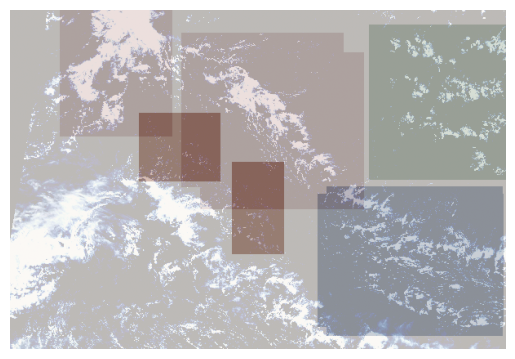

In [14]:
show_image_with_mask(img.permute(1, 2, 0).numpy(), mask.numpy())

## Модель

In [15]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.base = smp.Unet(
            encoder_name="resnet34",        
            encoder_weights="imagenet",     
            in_channels=3,                 
            classes=4                   
            )
    def forward(self, x):
        return self.base(x)

## Функция потерь

In [16]:
# Define Dice Loss
class DiceLoss(nn.Module):
    def __init__(self):
        super(DiceLoss, self).__init__()

    def forward(self, inputs, targets, smooth=1):
        inputs = torch.sigmoid(inputs)  # Apply sigmoid to get probabilities
        inputs = inputs.view(-1)
        targets = targets.view(-1)
        intersection = (inputs * targets).sum()
        dice = (2. * intersection + smooth) / (inputs.sum() + targets.sum() + smooth)
        return 1 - dice

#Define BCE + Dice Loss
class BCEDiceLoss(nn.Module):
    def __init__(self):
        super(BCEDiceLoss, self).__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

    def forward(self, inputs, targets):
        bce_loss = self.bce(inputs, targets)
        dice_loss = self.dice(inputs, targets)
        return bce_loss + dice_loss



## Обучение

In [17]:
class EarlyStopping:
    def __init__(self, patience=5, verbose=False, delta=0):
        """
        Early stops the training if validation loss doesn't improve after a given patience.
        """
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.delta = delta  # Minimum change to qualify as an improvement

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

In [18]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = UNet()

model = model.to('cuda')

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)  

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6)

criterion = BCEDiceLoss()

dice_loss = DiceLoss()


In [19]:
device

device(type='cuda')

In [20]:
print(f"torch.cuda.is_available(): {torch.cuda.is_available()}")
print(f"torch.version.cuda: {torch.version.cuda}")

torch.cuda.is_available(): True
torch.version.cuda: 13.2


In [21]:
def validate(model):
    model.eval()
    with torch.no_grad():
        running_loss = 0.0
        dice = 0.0
        for images, masks in tqdm(val_loader, desc="Validation"):
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            running_loss += loss.item()
            dice += 1 - dice_loss(outputs, masks).item()
    return running_loss/len(val_loader) , dice/len(val_loader)

In [22]:
def train_model(model, optimizer, early_stopping): 
    train_history = []
    val_history = []
    best_loss = 1.0
    model.train()
    n_epochs=100
    for epoch in range(n_epochs):
        running_loss = 0.0
        for images, masks in tqdm(train_loader, desc="Training"):
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        
        train_loss = running_loss/len(train_loader)

        val_loss, dice = validate(model)
        
        scheduler.step(epoch + (1 / len(train_loader)))
        print(f'Epoch {epoch}, Loss: {train_loss:.4f}, Val loss: {val_loss:.4f}, Dice coef: {dice:.4f}')
       
        train_history.append(train_loss)
        val_history.append(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            torch.save(model.state_dict(), 'best_unet.pt')
            print('Validation loss decreased. Model saved!')

        epoch+=1

        # if epoch > 5:
        #     break

        early_stopping(val_loss)
        if early_stopping.early_stop:
            break
    
    return train_history, val_history

In [23]:
early_stopping = EarlyStopping()
train_history, val_history = train_model(model, optimizer, early_stopping)

Validation: 100%|██████████| 70/70 [00:31<00:00,  2.19it/s]


Epoch 0, Loss: 1.1746, Val loss: 0.9816, Dice coef: 0.3991
Validation loss decreased. Model saved!


Validation: 100%|██████████| 70/70 [00:36<00:00,  1.94it/s]


Epoch 1, Loss: 0.9401, Val loss: 0.8697, Dice coef: 0.4557
Validation loss decreased. Model saved!


Validation: 100%|██████████| 70/70 [00:33<00:00,  2.07it/s]


Epoch 2, Loss: 0.8561, Val loss: 0.8434, Dice coef: 0.4944
Validation loss decreased. Model saved!


... (46 outputs left out)

Validation: 100%|██████████| 70/70 [00:33<00:00,  2.08it/s]


Epoch 26, Loss: 0.7012, Val loss: 0.7271, Dice coef: 0.5650


Validation: 100%|██████████| 70/70 [00:33<00:00,  2.10it/s]

Epoch 27, Loss: 0.6970, Val loss: 0.7289, Dice coef: 0.5653


#### Коэффициент обученной модели 

Dice coef: 0.5653

## График обучения

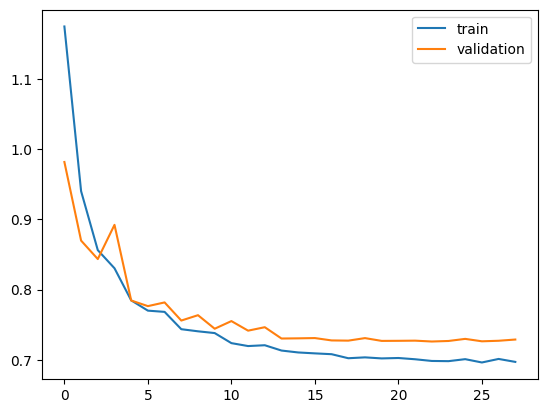

In [24]:
plt.plot(train_history, label='train')
plt.plot(val_history, label='validation')
plt.legend()   
plt.show()

## Подбор порогов

In [23]:
# Загружаем модель
model.load_state_dict(torch.load('best_unet.pt', weights_only=False))
model.eval()

# model.load_state_dict(torch.load('best_unet.pt'))
# model = model.to('cuda')

UNet(
  (base): Unet(
    (encoder): ResNetEncoder(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (relu): ReLU(inplace=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        )
        (1): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=Fa

Подберем пороги для значений значений веротностей принадлежности пикселей к классам, а также пороги минимального размера класса на изображении с целью увеличения Dice coef

In [24]:
# получаем вероятности классов на изображении, а также маски из валидационного датасета 
@torch.no_grad()
def get_probs(model, val_loader, device):
    model.eval()
    all_probs = []
    all_masks = []
    for images, masks in tqdm(val_loader, desc="Getting probabilities"):
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)
        probs = torch.sigmoid(outputs)

        all_probs.append(probs.cpu().numpy().astype(np.float32))
        all_masks.append(masks.cpu().numpy())

    return np.concatenate(all_probs, axis=0), np.concatenate(all_masks, axis=0) 

In [25]:
def score_thresholds(probs, masks, pixel_thresholds, min_squares, eps=1e-7):

    pixel_thresholds = np.asarray(pixel_thresholds, dtype=np.float32)
    min_squares = np.asarray(min_squares, dtype=np.int32)

    dices = []

    for c in range(4):
        # бинаризуем вероятности и маски по классу c
        pred = (probs[:, c] > pixel_thresholds[c])     
        targ = (masks[:, c] > 0.5)                     

        # предсказанная площадь класса на изображении
        area = pred.reshape(pred.shape[0], -1).sum(axis=1)

        # отсекаем площади меньше порога min_squares[c]
        pred[area < min_squares[c]] = False

        # считаем Dice для каждого класса
        inter = np.logical_and(pred, targ).sum()
        denom = pred.sum() + targ.sum()
        dice_c = (2.0 * inter + eps) / (denom + eps)
        dices.append(dice_c)


    return float(np.mean(dices)), np.array(dices, dtype=np.float32) # возсращаем средний Dice и массив Dice по классам


In [26]:
def make_objective(probs, masks):
    """
    Возвращает функцию потерь для оптимизации порогов.
    """
    def objective(trial):
        # Подбираем pixel threshold для каждого класса.
        pixel_thresholds = np.array([
            trial.suggest_float(f"pix_treshold_{c}", 0.01, 0.99)  
            for c in range(4)
        ], dtype=np.float32)

        # Подбираем минимальную площадь распознанного объекта для каждого класса.
        min_squares = np.array([
            trial.suggest_int(f"min_square_{c}", 0, 8000)    
            for c in range(4)
        ], dtype=np.int32)
        
        mean_dice, dice_per_class = score_thresholds(probs, masks, pixel_thresholds=pixel_thresholds, min_squares=min_squares)

        trial.set_user_attr("dice_per_class", dice_per_class.tolist())

        return mean_dice
    
    return objective

In [27]:
def run_threshold_search(probs, masks, n_trials=500, seed=42):
    """
      Подбираем оптимальные пороги (pixel_thresholds и min_squares) для каждого класса.
      Используем Optuna для поиска по 8 гиперпараметрам.
    """

    objective = make_objective(probs, masks)

    sampler = optuna.samplers.TPESampler(seed=seed) 

    pruner = optuna.pruners.MedianPruner(n_startup_trials=50) 

    study = optuna.create_study(
        direction="maximize",
        sampler=sampler,
        pruner=pruner
    ) 

    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)  

    best_params = study.best_params
    best_score = study.best_value

    best_pixel_thresholds = np.array([best_params[f"pix_treshold_{c}"] for c in range(4)], dtype=np.float32)
    best_min_squares = np.array([best_params[f"min_square_{c}"] for c in range(4)], dtype=np.int32)

    return best_pixel_thresholds, best_min_squares, float(best_score), study

In [28]:
@torch.no_grad()
def postprocess_logits_to_masks(logits, pixel_thresholds, min_squares):
    """
    Преобразуем логиты в бинарные маски с учетом порогов и минимальной площади.
    """
    device = logits.device
    B, C, H, W = logits.shape
    assert C == 4, "Ожидается 4 канала классов"

    probs = torch.sigmoid(logits)  

    pix_t = torch.tensor(pixel_thresholds, device=device, dtype=probs.dtype).view(1, C, 1, 1)
    min_sq = torch.tensor(min_squares, device=device, dtype=torch.long).view(1, C)

    pred = probs > pix_t  

    area = pred.flatten(2).sum(dim=2) 

    keep = area >= min_sq      
    pred = pred & keep.view(B, C, 1, 1)

    return pred.float()

In [29]:
probs, masks = get_probs(model, val_loader, device)
print("Collected:", probs.shape, masks.shape)

mean_dice_05, dice_pc_05 = score_thresholds(
    probs, masks,
    pixel_thresholds=[0.5, 0.5, 0.5, 0.5],
    min_squares=[0, 0, 0, 0],
)

print("Baseline (t=0.5, min_pix=0):", mean_dice_05, dice_pc_05)

best_pix_t, best_min_sq, best_dice, study = run_threshold_search(
    probs, masks,
    n_trials=250,
    seed=42
)


Getting probabilities: 100%|██████████| 70/70 [00:48<00:00,  1.44it/s]


Collected: (1110, 4, 416, 608) (1110, 4, 416, 608)


[I 2026-10-15 20:16:51,288] A new study created in memory with name: no-name-850bde21-abd9-4ffa-a857-1661e7138098


Baseline (t=0.5, min_pix=0): 0.6226578556419634 [0.5689113  0.7062389  0.57619786 0.6392833 ]


Best trial: 0. Best value: 0.576263:   0%|          | 1/250 [00:03<14:11,  3.42s/it]

[I 2026-10-15 20:16:54,704] Trial 0 finished with value: 0.5762633634620449 and parameters: {'pix_treshold_0': 0.37704931647041523, 'pix_treshold_1': 0.9417000202817178, 'pix_treshold_2': 0.727354062975177, 'pix_treshold_3': 0.5966853145130959, 'min_square_0': 1248, 'min_square_1': 1248, 'min_square_2': 464, 'min_square_3': 6930}. Best is trial 0 with value: 0.5762633634620449.


... (494 outputs left out)

Best trial: 206. Best value: 0.627708: 100%|█████████▉| 249/250 [11:25<00:02,  2.72s/it]

[I 2026-10-15 20:28:16,779] Trial 248 finished with value: 0.6272716744423589 and parameters: {'pix_treshold_0': 0.3560536763527062, 'pix_treshold_1': 0.586642556356867, 'pix_treshold_2': 0.2925061519527603, 'pix_treshold_3': 0.4937629064074459, 'min_square_0': 5341, 'min_square_1': 1302, 'min_square_2': 1284, 'min_square_3': 1617}. Best is trial 206 with value: 0.6277076497325202.


Best trial: 206. Best value: 0.627708: 100%|██████████| 250/250 [11:28<00:00,  2.75s/it]

[I 2026-10-15 20:28:19,477] Trial 249 finished with value: 0.6275019375659373 and parameters: {'pix_treshold_0': 0.33694734946527183, 'pix_treshold_1': 0.60924389121761, 'pix_treshold_2': 0.3208208868517418, 'pix_treshold_3': 0.49069865076595254, 'min_square_0': 5822, 'min_square_1': 1172, 'min_square_2': 1463, 'min_square_3': 1325}. Best is trial 206 with value: 0.6277076497325202.


In [30]:
print("Best mean dice:", best_dice)
print("Best pixel thresholds:", best_pix_t)
print("Best min_squares:", best_min_sq)

mean_dice_best, dice_pc_best = score_thresholds(
    probs, masks,
    pixel_thresholds=best_pix_t,
    min_squares=best_min_sq,
)
print("Re-check best:", mean_dice_best, dice_pc_best)


x, y = next(iter(val_loader))
x = x.to(device)
with torch.no_grad():
    logits = model(x)  

pred_masks = postprocess_logits_to_masks(
    logits,
    pixel_thresholds=best_pix_t,
    min_squares=best_min_sq
)
print("Pred masks:", pred_masks.shape, pred_masks.dtype)

Best mean dice: 0.6277076497325202
Best pixel thresholds: [0.30795473 0.6009276  0.34041655 0.4834873 ]
Best min_squares: [5657 1358 2335  920]
Re-check best: 0.6277076497325202 [0.58061147 0.7073802  0.5835291  0.6393099 ]
Pred masks: torch.Size([16, 4, 416, 608]) torch.float32


После подбора порогов Dice coef: 0.627708

## Визуализация

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6225708].


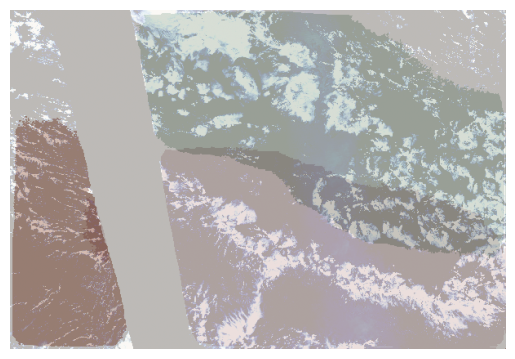

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.6225708].


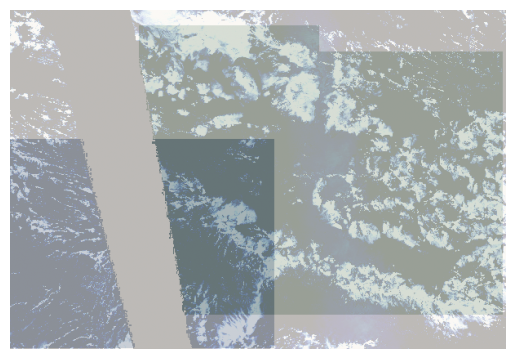

In [31]:
img, mask = val_dataset[10]
img = img.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    logits = model(img)          

pred =  postprocess_logits_to_masks(logits, best_pix_t, best_min_sq) 


show_image_with_mask(img[0].permute(1,2,0).cpu().numpy(), pred[0].cpu().numpy())
show_image_with_mask(img[0].permute(1,2,0).cpu().numpy(), mask.numpy())